# ПР-1 Юшко ТЦР-43
## Контрольована класифікація даних (завдання 2.3–2.6)

In [1]:
# Завантаження допоміжних файлів (utilities.py, датасети) — потрібно для Google Colab
import os, urllib.request
FILES = {
    "utilities.py": "https://raw.githubusercontent.com/PacktPublishing/Artificial-Intelligence-with-Python/master/Chapter%2002/code/utilities.py",
    "data_multivar_nb.txt": "https://raw.githubusercontent.com/PacktPublishing/Artificial-Intelligence-with-Python/master/Chapter%2002/code/data_multivar_nb.txt",
    "data_metrics.csv": "https://raw.githubusercontent.com/andrewwlong/classification_metrics_sklearn/master/data.csv",
}
for name, url in FILES.items():
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)
    print(name, "—", os.path.getsize(name), "байт")

utilities.py — 1386 байт
data_multivar_nb.txt — 4820 байт
data_metrics.csv — 406177 байт


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score
from utilities import visualize_classifier

## Завдання 2.3. Логістичний класифікатор (LR_1_task_3)

Predicted: [0 0 0 1 1 1 2 2 2 3 3 3]
Actual:    [0 0 0 1 1 1 2 2 2 3 3 3]
Training accuracy = 100.0 %


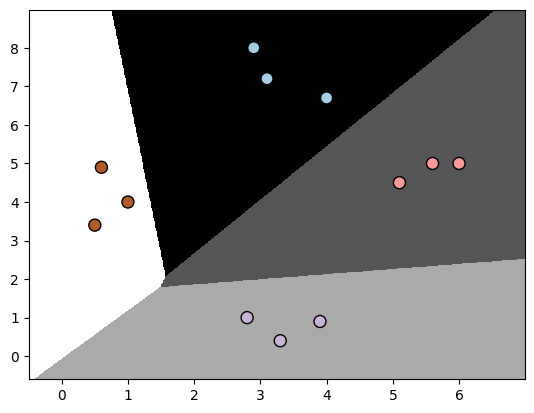

In [3]:
X = np.array([[3.1, 7.2], [4, 6.7], [2.9, 8], [5.1, 4.5],
              [6, 5], [5.6, 5], [3.3, 0.4],
              [3.9, 0.9], [2.8, 1],
              [0.5, 3.4], [1, 4], [0.6, 4.9]])
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3])

# liblinear працює за схемою «один проти всіх»; у нових версіях sklearn її треба задавати явно
from sklearn.multiclass import OneVsRestClassifier
classifier = OneVsRestClassifier(linear_model.LogisticRegression(solver='liblinear', C=1))
classifier.fit(X, y)
print("Predicted:", classifier.predict(X))
print("Actual:   ", y)
print("Training accuracy =", round(100 * (classifier.predict(X) == y).mean(), 2), "%")

visualize_classifier(classifier, X, y)

## Завдання 2.4. Наївний байєсовський класифікатор (LR_1_task_4)

Samples: 400 | features: 2 | classes: [0. 1. 2. 3.]
Accuracy of Naive Bayes classifier = 99.75 %


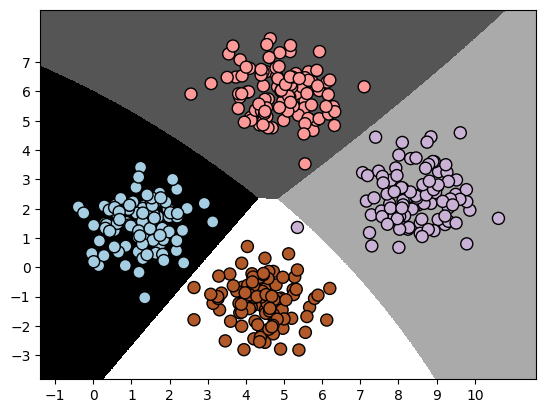

In [4]:
input_file = 'data_multivar_nb.txt'
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]
print("Samples:", X.shape[0], "| features:", X.shape[1], "| classes:", np.unique(y))

classifier = GaussianNB()
classifier.fit(X, y)
y_pred = classifier.predict(X)
accuracy = 100.0 * (y == y_pred).sum() / X.shape[0]
print("Accuracy of Naive Bayes classifier =", round(accuracy, 2), "%")
visualize_classifier(classifier, X, y)

Accuracy of the new classifier = 100.0 %


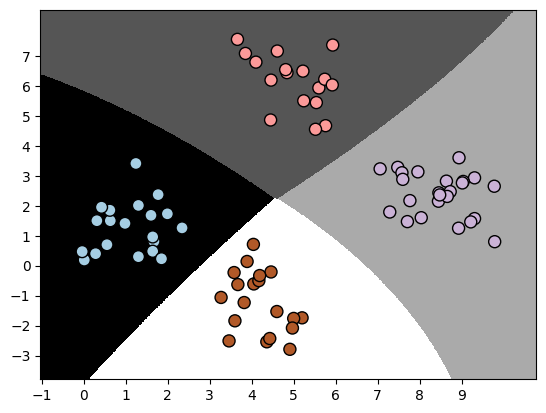

In [5]:
# Прогін 1: розбиття 80/20, random_state=3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)
classifier_new = GaussianNB()
classifier_new.fit(X_train, y_train)
y_test_pred = classifier_new.predict(X_test)
accuracy = 100.0 * (y_test == y_test_pred).sum() / X_test.shape[0]
print("Accuracy of the new classifier =", round(accuracy, 2), "%")
visualize_classifier(classifier_new, X_test, y_test)

In [6]:
num_folds = 3
accuracy_values = cross_val_score(classifier, X, y, scoring='accuracy', cv=num_folds)
print("Accuracy: " + str(round(100 * accuracy_values.mean(), 2)) + "%")
precision_values = cross_val_score(classifier, X, y, scoring='precision_weighted', cv=num_folds)
print("Precision: " + str(round(100 * precision_values.mean(), 2)) + "%")
recall_values = cross_val_score(classifier, X, y, scoring='recall_weighted', cv=num_folds)
print("Recall: " + str(round(100 * recall_values.mean(), 2)) + "%")
f1_values = cross_val_score(classifier, X, y, scoring='f1_weighted', cv=num_folds)
print("F1: " + str(round(100 * f1_values.mean(), 2)) + "%")

Accuracy: 99.75%
Precision: 99.76%
Recall: 99.75%
F1: 99.75%


Accuracy of the classifier (run 2) = 100.0 %


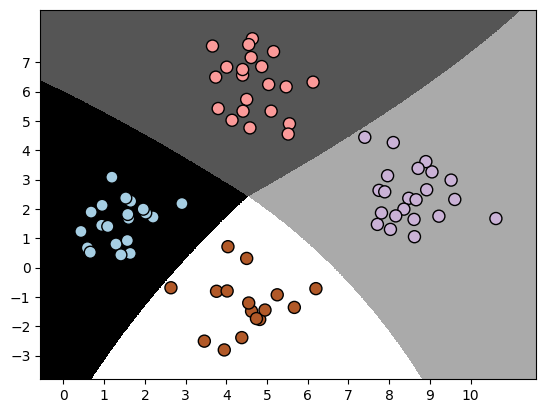

In [7]:
# Прогін 2: інше розбиття (random_state=7)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=7)
classifier_new2 = GaussianNB()
classifier_new2.fit(X_train2, y_train2)
y_test_pred2 = classifier_new2.predict(X_test2)
accuracy2 = 100.0 * (y_test2 == y_test_pred2).sum() / X_test2.shape[0]
print("Accuracy of the classifier (run 2) =", round(accuracy2, 2), "%")
visualize_classifier(classifier_new2, X_test2, y_test2)

## Завдання 2.5. Метрики якості класифікації (LR_1_task_5)

In [8]:
df = pd.read_csv('data_metrics.csv')
thresh = 0.5
df['predicted_RF'] = (df.model_RF >= thresh).astype('int')
df['predicted_LR'] = (df.model_LR >= thresh).astype('int')
print(df.head())

   actual_label  model_RF  model_LR  predicted_RF  predicted_LR
0             1  0.639816  0.531904             1             1
1             0  0.490993  0.414496             0             0
2             1  0.623815  0.569883             1             1
3             1  0.506616  0.443674             1             0
4             0  0.418302  0.369532             0             0


In [9]:
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score

def yushko_find_TP(y_true, y_pred):
    # true positives (y_true = 1, y_pred = 1)
    return sum((y_true == 1) & (y_pred == 1))

def yushko_find_FN(y_true, y_pred):
    # false negatives (y_true = 1, y_pred = 0)
    return sum((y_true == 1) & (y_pred == 0))

def yushko_find_FP(y_true, y_pred):
    # false positives (y_true = 0, y_pred = 1)
    return sum((y_true == 0) & (y_pred == 1))

def yushko_find_TN(y_true, y_pred):
    # true negatives (y_true = 0, y_pred = 0)
    return sum((y_true == 0) & (y_pred == 0))

def yushko_find_conf_matrix_values(y_true, y_pred):
    TP = yushko_find_TP(y_true, y_pred)
    FN = yushko_find_FN(y_true, y_pred)
    FP = yushko_find_FP(y_true, y_pred)
    TN = yushko_find_TN(y_true, y_pred)
    return TP, FN, FP, TN

def yushko_confusion_matrix(y_true, y_pred):
    TP, FN, FP, TN = yushko_find_conf_matrix_values(y_true, y_pred)
    return np.array([[TN, FP], [FN, TP]])

y_true = df.actual_label.values
print('TP:', yushko_find_TP(y_true, df.predicted_RF.values))
print('FN:', yushko_find_FN(y_true, df.predicted_RF.values))
print('FP:', yushko_find_FP(y_true, df.predicted_RF.values))
print('TN:', yushko_find_TN(y_true, df.predicted_RF.values))
print("\nsklearn confusion_matrix RF:\n", confusion_matrix(y_true, df.predicted_RF.values))
print("yushko_confusion_matrix RF:\n", yushko_confusion_matrix(y_true, df.predicted_RF.values))
print("yushko_confusion_matrix LR:\n", yushko_confusion_matrix(y_true, df.predicted_LR.values))

assert np.array_equal(yushko_confusion_matrix(y_true, df.predicted_RF.values),
                      confusion_matrix(y_true, df.predicted_RF.values)), 'yushko_confusion_matrix() is not correct for RF'
assert np.array_equal(yushko_confusion_matrix(y_true, df.predicted_LR.values),
                      confusion_matrix(y_true, df.predicted_LR.values)), 'yushko_confusion_matrix() is not correct for LR'
print("\nConfusion matrix check: OK")

TP: 5047
FN: 2832
FP: 2360
TN: 5519

sklearn confusion_matrix RF:
 [[5519 2360]
 [2832 5047]]
yushko_confusion_matrix RF:
 [[5519 2360]
 [2832 5047]]
yushko_confusion_matrix LR:
 [[5425 2454]
 [3600 4279]]

Confusion matrix check: OK


In [10]:
def yushko_accuracy_score(y_true, y_pred):
    TP, FN, FP, TN = yushko_find_conf_matrix_values(y_true, y_pred)
    return (TP + TN) / (TP + FN + FP + TN)

def yushko_recall_score(y_true, y_pred):
    TP, FN, FP, TN = yushko_find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FN)

def yushko_precision_score(y_true, y_pred):
    TP, FN, FP, TN = yushko_find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FP)

def yushko_f1_score(y_true, y_pred):
    recall = yushko_recall_score(y_true, y_pred)
    precision = yushko_precision_score(y_true, y_pred)
    return 2 * (precision * recall) / (precision + recall)

checks = [(yushko_accuracy_score, accuracy_score, 'accuracy'),
          (yushko_recall_score, recall_score, 'recall'),
          (yushko_precision_score, precision_score, 'precision'),
          (yushko_f1_score, f1_score, 'f1')]
for mine, ref, name in checks:
    for col in ['predicted_RF', 'predicted_LR']:
        assert np.isclose(mine(y_true, df[col].values), ref(y_true, df[col].values)), f'yushko_{name}_score failed on {col}'
print("All metric checks: OK\n")

for name, f in [('Accuracy', yushko_accuracy_score), ('Recall', yushko_recall_score),
                ('Precision', yushko_precision_score), ('F1', yushko_f1_score)]:
    print('%s RF: %.3f' % (name, f(y_true, df.predicted_RF.values)))
    print('%s LR: %.3f' % (name, f(y_true, df.predicted_LR.values)))

All metric checks: OK

Accuracy RF: 0.671
Accuracy LR: 0.616
Recall RF: 0.641
Recall LR: 0.543
Precision RF: 0.681
Precision LR: 0.636
F1 RF: 0.660
F1 LR: 0.586


In [11]:
for t in [0.5, 0.25]:
    pred = (df.model_RF >= t).astype('int').values
    print('scores with threshold = %s' % t)
    print('Accuracy RF: %.3f' % yushko_accuracy_score(y_true, pred))
    print('Recall RF: %.3f' % yushko_recall_score(y_true, pred))
    print('Precision RF: %.3f' % yushko_precision_score(y_true, pred))
    print('F1 RF: %.3f' % yushko_f1_score(y_true, pred))
    print('')

scores with threshold = 0.5
Accuracy RF: 0.671
Recall RF: 0.641
Precision RF: 0.681
F1 RF: 0.660

scores with threshold = 0.25
Accuracy RF: 0.502


Recall RF: 1.000
Precision RF: 0.501


F1 RF: 0.668



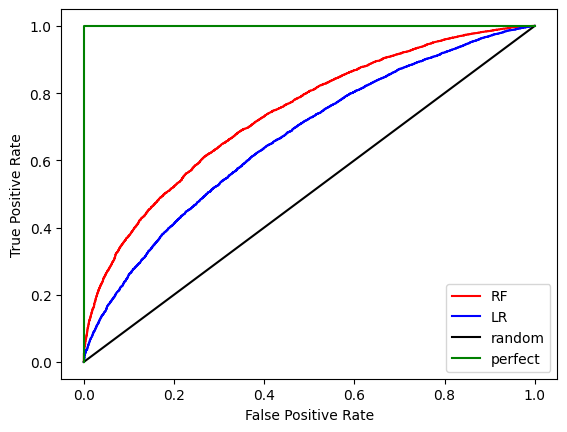

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr_RF, tpr_RF, thresholds_RF = roc_curve(y_true, df.model_RF.values)
fpr_LR, tpr_LR, thresholds_LR = roc_curve(y_true, df.model_LR.values)

plt.figure()
plt.plot(fpr_RF, tpr_RF, 'r-', label='RF')
plt.plot(fpr_LR, tpr_LR, 'b-', label='LR')
plt.plot([0, 1], [0, 1], 'k-', label='random')
plt.plot([0, 0, 1, 1], [0, 1, 1, 1], 'g-', label='perfect')
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

AUC RF:0.738
AUC LR:0.666


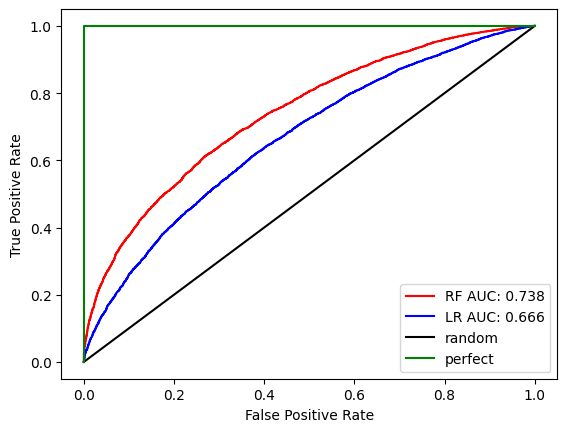

In [13]:
auc_RF = roc_auc_score(y_true, df.model_RF.values)
auc_LR = roc_auc_score(y_true, df.model_LR.values)
print('AUC RF:%.3f' % auc_RF)
print('AUC LR:%.3f' % auc_LR)

plt.figure()
plt.plot(fpr_RF, tpr_RF, 'r-', label='RF AUC: %.3f' % auc_RF)
plt.plot(fpr_LR, tpr_LR, 'b-', label='LR AUC: %.3f' % auc_LR)
plt.plot([0, 1], [0, 1], 'k-', label='random')
plt.plot([0, 0, 1, 1], [0, 1, 1, 1], 'g-', label='perfect')
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

## Завдання 2.6. Класифікація машиною опорних векторів (LR_1_task_6)

In [14]:
data = np.loadtxt('data_multivar_nb.txt', delimiter=',')
X, y = data[:, :-1], data[:, -1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)

models = {
    'Naive Bayes (GaussianNB)': GaussianNB(),
    'SVM, linear kernel': SVC(kernel='linear', C=1.0),
    'SVM, RBF kernel': SVC(kernel='rbf', C=1.0, gamma='scale'),
}
rows = []
for name, model in models.items():
    train_acc = 100 * (model.fit(X, y).predict(X) == y).mean()
    model.fit(X_train, y_train)
    test_acc = 100 * (model.predict(X_test) == y_test).mean()
    cv = {s: 100 * cross_val_score(model, X, y, scoring=s, cv=3).mean()
          for s in ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']}
    rows.append([name, round(train_acc, 2), round(test_acc, 2)] + [round(v, 2) for v in cv.values()])

results = pd.DataFrame(rows, columns=['Model', 'Full-data acc, %', 'Test acc, %', 'CV Accuracy, %', 'CV Precision, %', 'CV Recall, %', 'CV F1, %'])
print(results.to_string(index=False))

                   Model  Full-data acc, %  Test acc, %  CV Accuracy, %  CV Precision, %  CV Recall, %  CV F1, %
Naive Bayes (GaussianNB)             99.75        100.0           99.75            99.76         99.75     99.75
      SVM, linear kernel            100.00        100.0           99.75            99.76         99.75     99.75
         SVM, RBF kernel             99.75        100.0           99.75            99.76         99.75     99.75


              precision    recall  f1-score   support

         0.0      1.000     1.000     1.000        20
         1.0      1.000     1.000     1.000        17
         2.0      1.000     1.000     1.000        24
         3.0      1.000     1.000     1.000        19

    accuracy                          1.000        80
   macro avg      1.000     1.000     1.000        80
weighted avg      1.000     1.000     1.000        80

Confusion matrix:
 [[20  0  0  0]
 [ 0 17  0  0]
 [ 0  0 24  0]
 [ 0  0  0 19]]


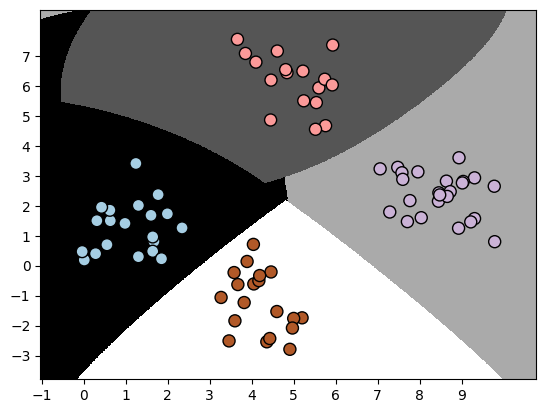

In [15]:
svm_classifier = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_classifier.fit(X_train, y_train)
y_test_pred = svm_classifier.predict(X_test)
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_test_pred))
visualize_classifier(svm_classifier, X_test, y_test)